# Recovering a fault-bounded sedimentary basin

The [recovering sharp features notebook](recovering_sharp_features.ipynb) introduced the IRLS (L1-norm style) solver and showed that it recovers sharp fault offsets which the default smooth (L2-norm) solver smears out.
Here we use it in a realistic exploration scenario:

- the topography comes from the [Bishop model](https://wiki.seg.org/wiki/Bishop_Model), a community synthetic model with realistic, rugged topography, loaded with [load_bishop_model](../api/generated/invert4geom.load_bishop_model.rst)
- an **arcuate normal fault** offsets that topography, dropping the ground to its east by up to 700 m, and **sediment floods the resulting low ground**, filling all topography below 800 m elevation
- **basement outcrops** wherever it stands above the 800 m fill level, while the sediment-covered basin is deepest directly against the fault, which is hidden beneath the fill near the surface contact between outcrop and cover
- the target of the inversion is the **basement surface beneath the cover**, constrained by two types of hard data: wherever basement outcrops its elevation is known exactly (it is the ground surface), and 4 **boreholes** through the sediment give the basement depth at points within the basin.

This notebook performs inversions with and L2-norm solver, the IRLS L1-norm solver, and introduces a fault-informed inversion, where the fault trace is known, and the horizontal gradient penalties of the IRLS solver are discarded at those locations, allowing sharp gradients where the fault is known to be. 

## Import packages

In [1]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import verde as vd
import xarray as xr
from tqdm.autonotebook import tqdm

import invert4geom

sns.set_theme()

## Load the Bishop topography

We download the Bishop model (cached after the first call), resample it to 600 m resolution, select a 40 x 30 km subregion, and shift it so its lowest point sits at 0 m elevation.
This rugged surface, with about 1.9 km of relief, is the topography we will fault and then partially flood with sediment.

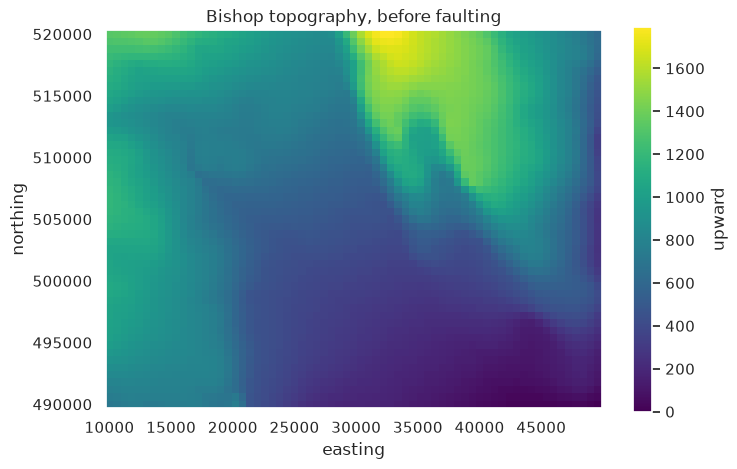

(600.0, (10000.0, 49600.0, 490000.0, 520000.0), 0.0, 1794.0, 'g')

In [2]:
topography = invert4geom.load_bishop_model().basement_topo

spacing = 600

topography = invert4geom.resample_grid(
    topography,
    # a whole number of 600 m cells in each direction, so the spacing stays exact
    region=(10e3, 49.6e3, 490e3, 520e3),
    spacing=spacing,
)

# shift so the lowest point is at 0 m elevation
topography = (topography - topography.min()).rename("upward")

topography.plot(figsize=(8, 5), cmap="viridis")
plt.gca().set_aspect("equal")
plt.title("Bishop topography, before faulting")
plt.show()

invert4geom.get_grid_info(topography)

## Build the geology: outcrop, cover, and a buried fault

We create the geology in two steps:

1. **Fault the topography**: an arcuate, north-south trending normal fault drops the ground east of it, by up to 700 m directly against the fault, with the offset tapering along strike and decaying gradually eastwards. The result is the **basement topography**.
2. **Flood it with sediment**: sediment fills in all of the faulted topography below 800 m elevation. Wherever the basement stands above 800 m it outcrops and the ground surface is the basement itself; everywhere else the ground surface is the flat top of the sediment fill at 800 m.

The deepest sediment sits directly against the fault.
Where the footwall next to the fault also dips below the fill level, the fault scarp is completely buried and the mapped contact between outcrop and cover lies west of the fault itself.

In [3]:
# the fault: an arcuate trace, concave towards the basin (east), with the basement
# dropping sharply on its east side, then decaying gradually eastwards and tapering
# out along strike
displacement = 700.0  # maximum offset, directly against the fault
drag_length = 12e3  # e-folding distance of the eastward decay
taper_width = 15e3  # along-strike half-width of the offset

sediment_level = 800.0

In [4]:
easting2d, northing2d = np.meshgrid(topography.easting, topography.northing)
e0 = float(topography.easting.min())
n0 = float(topography.northing.min())
basin_center_northing = float(topography.northing.mean())


def fault_trace(northing):
    """easting of the basin-bounding fault as a function of northing"""
    return e0 + 15.1e3 + 3e3 * ((northing - basin_center_northing) / 15.1e3) ** 2

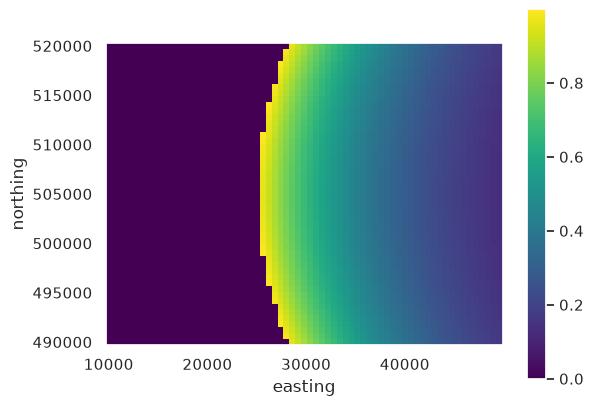

In [5]:
distance_east_of_fault = topography.easting - fault_trace(topography.northing)
drag = xr.where(
    distance_east_of_fault >= 0, np.exp(-distance_east_of_fault / drag_length), 0.0
)
drag.T.plot().axes.set_aspect("equal")

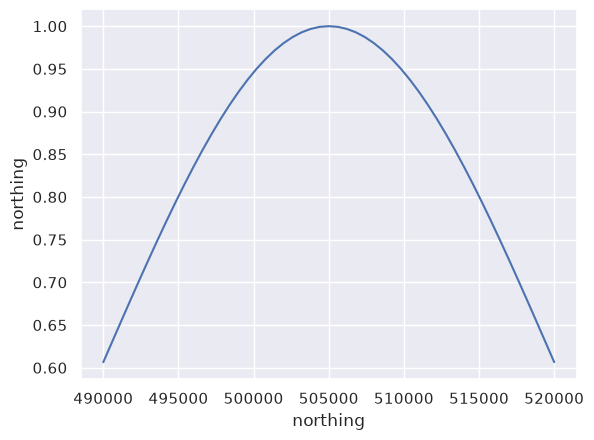

In [6]:
taper = np.exp(
    -((topography.northing - basin_center_northing) ** 2) / (2 * taper_width**2)
)
taper.plot()

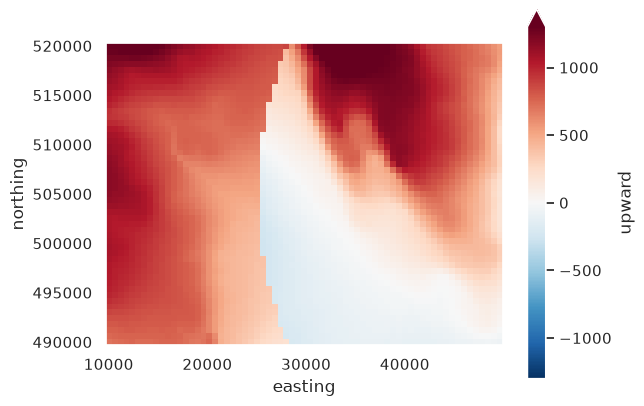

In [7]:
# the faulted topography is the true basement surface
true_basement = (topography - displacement * taper * drag).rename("upward")
true_basement.plot(robust=True).axes.set_aspect("equal")

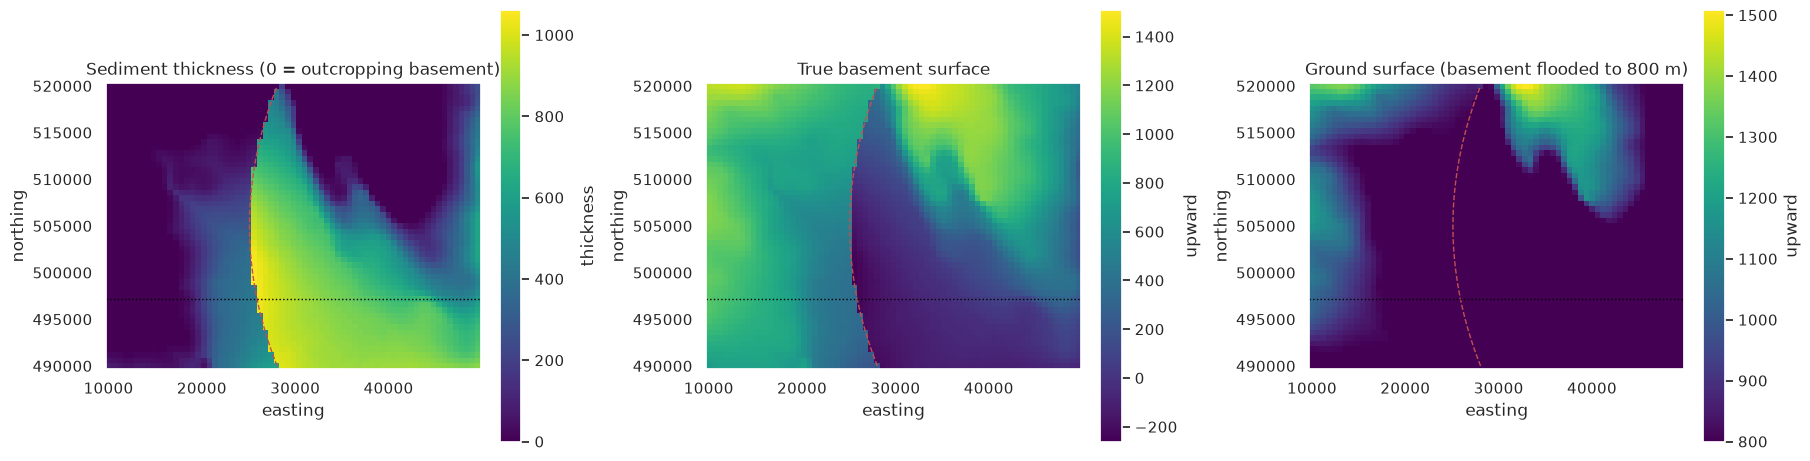

In [8]:
# sediment floods the low ground, filling everything below `sediment_level`
sediment_thickness = (sediment_level - true_basement).clip(min=0).rename("thickness")
outcrop = (sediment_thickness == 0).values  # where basement reaches the ground surface

# the ground surface: outcropping basement, or the flat top of the sediment fill
surface = true_basement.clip(min=sediment_level).rename("upward")

# the map-view trace of the fault, as vertices, which we later give to the
# inversion. In a real survey these would be digitized from a map, or picked off
# the gravity gradient as in the sharp features notebook.
trace_northing = np.linspace(n0, float(topography.northing.max()), 100)
fault_trace_vertices = pd.DataFrame(
    {"easting": fault_trace(trace_northing), "northing": trace_northing}
)

# the west-east profile used throughout, through the center of the basin
profile_northing = float(surface.northing.sel(northing=n0 + 7000, method="nearest"))

titles = [
    "Sediment thickness (0 = outcropping basement)",
    "True basement surface",
    f"Ground surface (basement flooded to {sediment_level:.0f} m)",
]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), constrained_layout=True)
for ax, grid, title in zip(
    axes, [sediment_thickness, true_basement, surface], titles, strict=True
):
    grid.plot(ax=ax, cmap="viridis", center=False)
    ax.plot(fault_trace_vertices.easting, fault_trace_vertices.northing, "r--", lw=1)
    ax.axhline(profile_northing, color="black", ls=":", lw=1)
    ax.set_title(title)
    ax.set_aspect("equal")
plt.show()

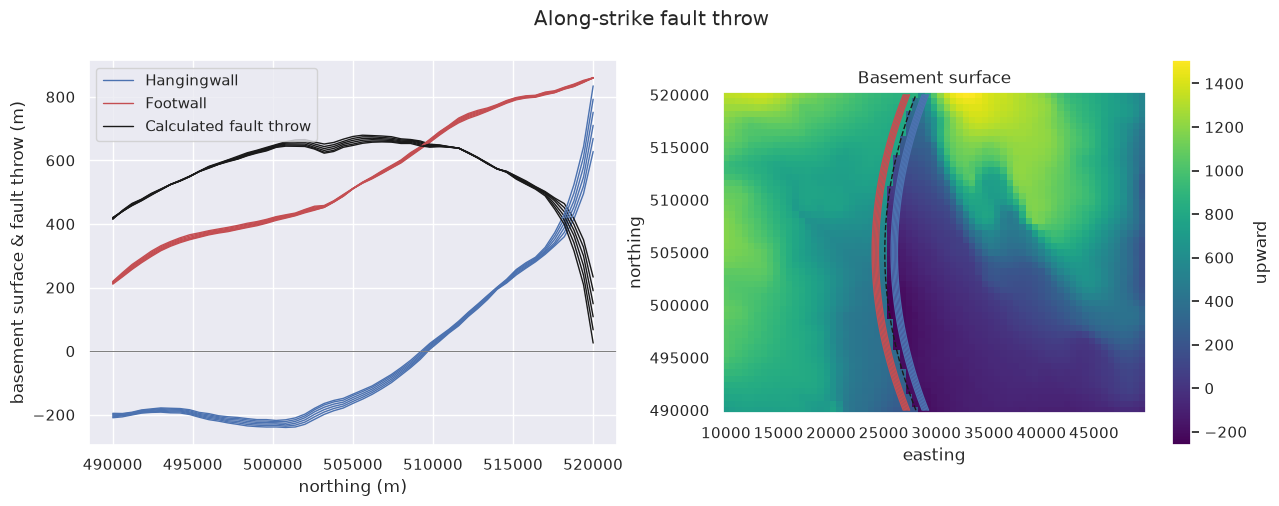

In [9]:
offsets = np.linspace(spacing, spacing * 2, 6)

northings = surface.northing.values
nd = xr.DataArray(northings, dims="northing", coords={"northing": surface.northing})

results = {}
for o in offsets:
    west = xr.DataArray(fault_trace(northings) - o, dims="northing")
    east = xr.DataArray(fault_trace(northings) + o, dims="northing")

    footwall_basement = (true_basement.interp(easting=west, northing=nd)).values

    hangingwall_basement = (true_basement.interp(easting=east, northing=nd)).values

    true_throw = (
        true_basement.interp(easting=west, northing=nd)
        - true_basement.interp(easting=east, northing=nd)
    ).values

    fault = {
        "footwall_basement": footwall_basement,
        "hangingwall_basement": hangingwall_basement,
        "true_throw": true_throw,
    }
    results[o] = fault

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for i, (offset, v) in enumerate(results.items()):
    ax = axes[0]
    if i == 0:
        label1 = "Hangingwall"
        label2 = "Footwall"
        label3 = "Calculated fault throw"
    else:
        label1, label2, label3 = None, None, None
    ax.plot(northings, v["hangingwall_basement"], "b", lw=1, label=label1)
    ax.plot(northings, v["footwall_basement"], "r", lw=1, label=label2)
    ax.plot(northings, v["true_throw"], "k", lw=1, label=label3)
    ax.axhline(0, color="gray", lw=0.5)
    ax.set_xlabel("northing (m)")
    ax.set_ylabel("basement surface & fault throw (m)")

    ax = axes[1]
    if i == 0:
        true_basement.plot(ax=ax, cmap="viridis", center=False)
        ax.plot(
            fault_trace_vertices.easting, fault_trace_vertices.northing, "k--", lw=1
        )
        # ax.hlines(profile_northing, float(topography.easting.min()), float(topography.easting.max()), 'k')
    ax.plot(
        fault_trace_vertices.easting - offset, fault_trace_vertices.northing, "r", lw=1
    )
    ax.plot(
        fault_trace_vertices.easting + offset, fault_trace_vertices.northing, "b", lw=1
    )
    ax.set_title("Basement surface")
    ax.set_aspect("equal")

axes[0].legend()

fig.suptitle("Along-strike fault throw")
plt.show()

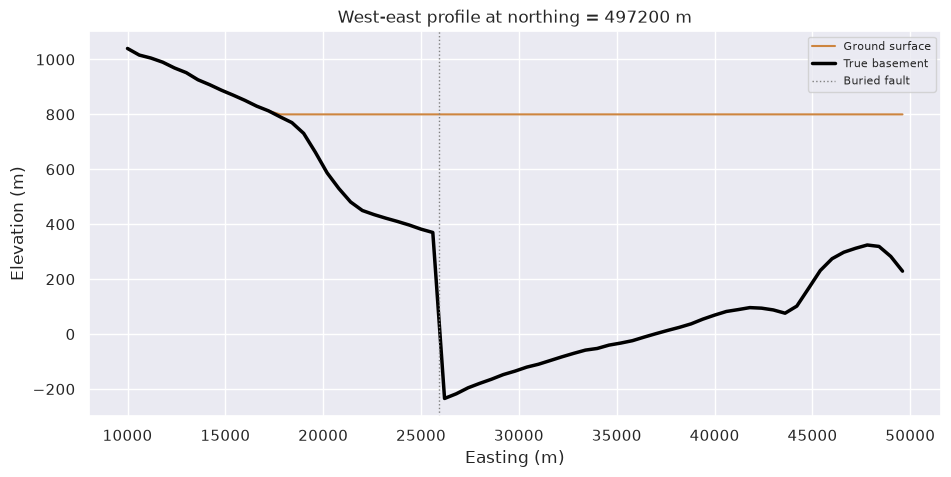

In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
surface.sel(northing=profile_northing).plot(
    ax=ax, color="peru", lw=1.5, label="Ground surface"
)
true_basement.sel(northing=profile_northing).plot(
    ax=ax, color="black", lw=2.5, label="True basement"
)
ax.axvline(
    fault_trace(profile_northing), color="gray", ls=":", lw=1, label="Buried fault"
)
ax.set_title(f"West-east profile at northing = {profile_northing:.0f} m")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Elevation (m)")
ax.legend(fontsize=8)
plt.show()

## Create the true model

The sediment is less dense than the basement, giving a density contrast of 400 kg/m$^3$ across the basement surface.
We set the reference level to the median basement elevation and discretize the true basement surface into prisms, viewing the model in 3D with semi-transparent prisms.
The buried fault scarp is visible as the sharp step within the basin.

```{note}
The density contrast is 400 kg/m$^3$ *everywhere*, including where the basement outcrops.
At first glance that seems wrong: at the outcrops the material above the basement surface is air, not sediment, suggesting a rock-air contrast of ~2670 kg/m$^3$ there.
The constant 400 kg/m$^3$ is correct because of what the prism layer represents.
The gravity data are assumed to be terrain corrected (see the next section), so the only source left in them is the **mass deficit of the sediment**: the volume between the basement surface and the ground surface where basement density is replaced by sediment density, a contrast of 400 kg/m$^3$.
At an outcrop there is no sediment and therefore no residual source at all — not a 2670 kg/m$^3$ one.

The prism layer is built between the basement surface and the constant reference level `zref` rather than up to the ground surface, but the difference between the two is a layer bounded by the *known* ground surface, which is a fixed, computable field that belongs with the terrain correction.
For an outcropping column, where the basement surface *is* the ground surface, the prism layer and that known layer exactly cancel, correctly producing zero anomaly — but the cancellation only works if the contrast is the same 400 kg/m$^3$ everywhere.
Assigning a rock-air contrast at the outcrops would instead inject spurious signal proportional to the (already known) outcrop topography.
```

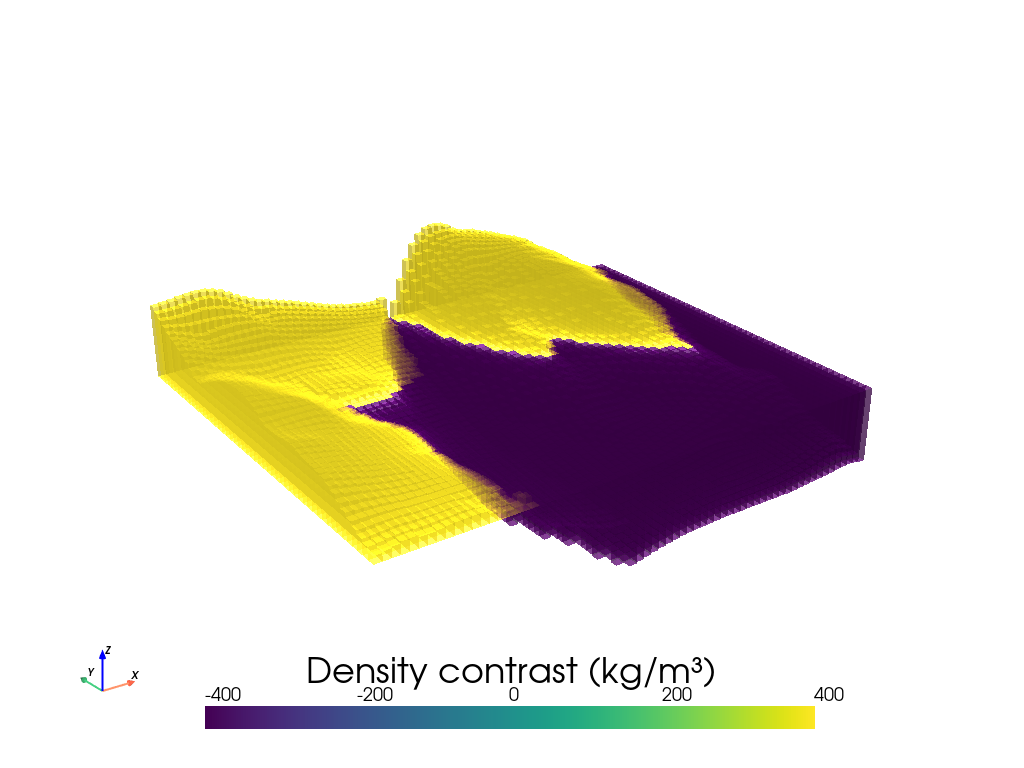

In [11]:
density_contrast = 400
zref = float(true_basement.median())

true_model = invert4geom.create_model(
    zref=zref,
    density_contrast=density_contrast,
    topography=true_basement.to_dataset(),
)

# 3D view of the prism model, semi-transparent and vertically exaggerated
true_model.inv.plot_model(
    color_by="density",
    opacity=0.5,
    zscale=8,
    elevation=25,
    azimuth=-35,
)

## Constraints: outcrops and boreholes

Wherever basement outcrops, its elevation is known exactly, so every outcrop cell becomes a constraint point.
Within the basin we add six boreholes which reached basement, sampling the true basement elevation at each with [sample_grids](../api/generated/invert4geom.sample_grids.rst).

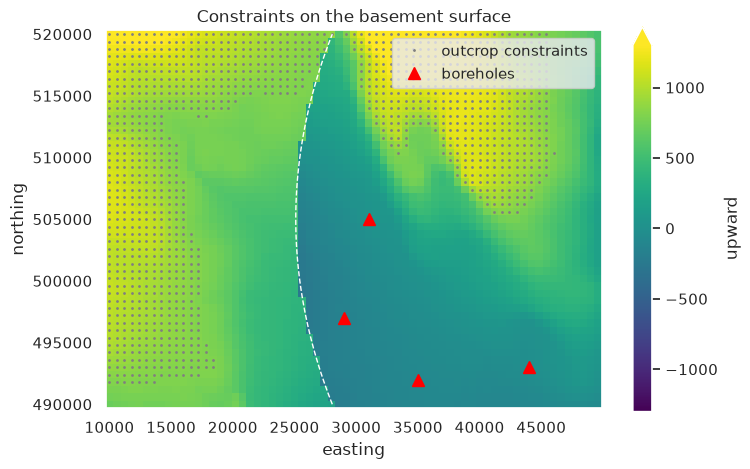

In [12]:
# every outcropping cell is a constraint on the basement elevation. These fall
# exactly on the model grid nodes, so we flag them with `grid_points`, which lets us
# supply them to `create_topography` as a grid instead of as points.
outcrop_constraints = pd.DataFrame(
    {
        "easting": easting2d[outcrop],
        "northing": northing2d[outcrop],
        "upward": true_basement.values[outcrop],
        "grid_points": True,
    }
)

# borehole locations within the basin
boreholes = pd.DataFrame(
    {
        "easting": [e0 + e for e in [19000, 21000, 25000, 34000]],
        "northing": [n0 + n for n in [7000, 15000, 2000, 3000]],
    }
)
boreholes = invert4geom.sample_grids(boreholes, true_basement, sampled_name="upward")

# the boreholes are between the grid nodes, so they aren't part of the grid
boreholes["grid_points"] = False

constraint_points = pd.concat([outcrop_constraints, boreholes], ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 5))
true_basement.plot(ax=ax, cmap="viridis", robust=True)
ax.plot(
    constraint_points[constraint_points.grid_points].easting,
    constraint_points[constraint_points.grid_points].northing,
    ".",
    color="gray",
    markersize=2,
    label="outcrop constraints",
)
ax.plot(
    constraint_points[~constraint_points.grid_points].easting,
    constraint_points[~constraint_points.grid_points].northing,
    "^",
    color="red",
    markersize=9,
    label="boreholes",
)
ax.plot(fault_trace(trace_northing), trace_northing, color="white", ls="--", lw=1)
ax.set_aspect("equal")
ax.set_title("Constraints on the basement surface")
ax.legend(loc="upper right")
plt.show()

## Create the starting model

Wherever basement outcrops its elevation is already known *on the model grid*, so instead of interpolating every constraint point we hand [create_topography](../api/generated/invert4geom.create_topography.rst) that partially-complete grid as `grid_to_fill`.
Only its missing values, the sediment-covered cells, are then interpolated, leaving the outcropping cells exactly as they are
The points used to fill the gap are the constraint points which aren't already part of the grid, i.e. those with `grid_points` set to False: the boreholes.

Here we fill with PyGMT's tensioned minimum curvature (`method="pygmt"`), which is well suited to interpolating a hole surrounded by known values.
A `tension` of 0.25 is the usual recommendation for topography; the untensioned minimum curvature solution (`tension=0`) overshoots below the deepest borehole, while a fully harmonic surface (`tension=1`) is pulled too flat.
Interpolating all the constraint points instead, as the [other how-to notebooks](adhering_to_point_measurements.ipynb) do, gives a similar overall error but smooths the known outcrops by up to ~100 m; filling only the gap honors them exactly.

Passing the ground surface as an `upper_confining_layer` keeps the interpolation (and later the inversion) from placing basement above the ground.
The starting basement matches the outcrops and boreholes exactly but, with no information between them, smoothly interpolates across the buried fault.

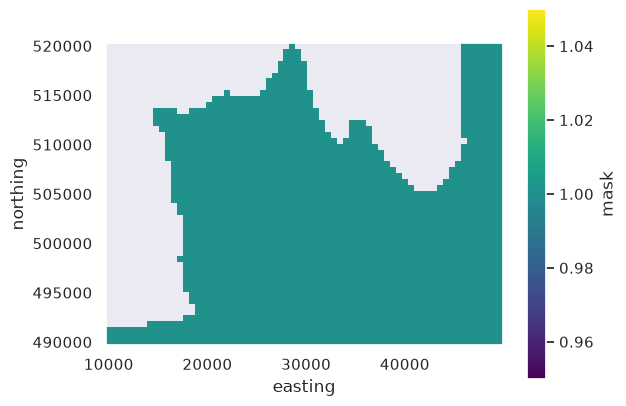

In [13]:
# the basement elevation is known exactly where it outcrops, and unknown (NaN)
# beneath the sediment cover
outcropping_basement = true_basement.where(sediment_thickness == 0)

# make a mask to drop prisms
mask = xr.where(np.isnan(outcropping_basement), 1, np.nan).rename("mask")
mask.plot().axes.set_aspect("equal")

In [14]:
# reduce the mask by several grid cells for to create a mask for the gravity data
# model_mask = invert4geom.buffer_edges(mask, cells=2, grow=True)
model_mask = mask
# model_mask.plot().axes.set_aspect('equal')

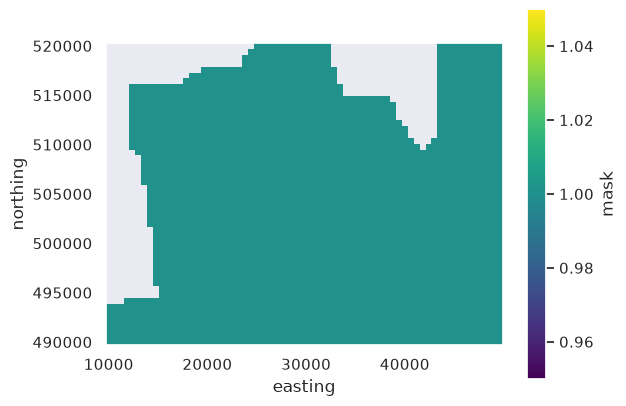

In [15]:
# reduce the mask by several grid cells for to create a mask for the gravity data
grav_mask = invert4geom.buffer_edges(mask, cells=4, grow=True)
grav_mask.plot().axes.set_aspect("equal")

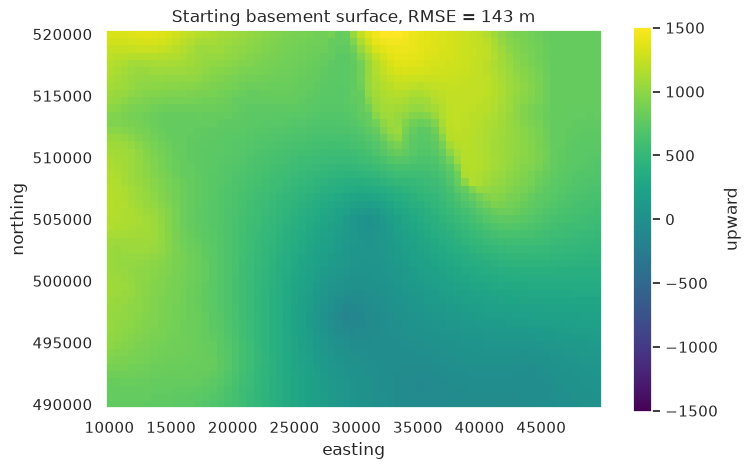

In [16]:
starting_topography = invert4geom.create_topography(
    region=(
        e0,
        float(surface.easting.max()),
        n0,
        float(surface.northing.max()),
    ),
    spacing=spacing,
    constraints_df=constraint_points,
    # fill the sediment-covered cells with tensioned minimum curvature, using the
    # constraint points which aren't already in the grid (the boreholes)
    method="pygmt",
    grid_to_fill=outcropping_basement,
    tension=0.25,
    upper_confining_layer=surface,
    dataset_to_add=model_mask,
)

starting_model = invert4geom.create_model(
    zref=zref,
    density_contrast=density_contrast,
    topography=starting_topography,
    upper_confining_layer=surface,
)

rmse = float(
    np.sqrt(np.mean((starting_topography.upward.values - true_basement.values) ** 2))
)

starting_topography.upward.plot(figsize=(8, 5), cmap="viridis")
plt.gca().set_aspect("equal")
plt.title(f"Starting basement surface, RMSE = {rmse:.0f} m")
plt.show()

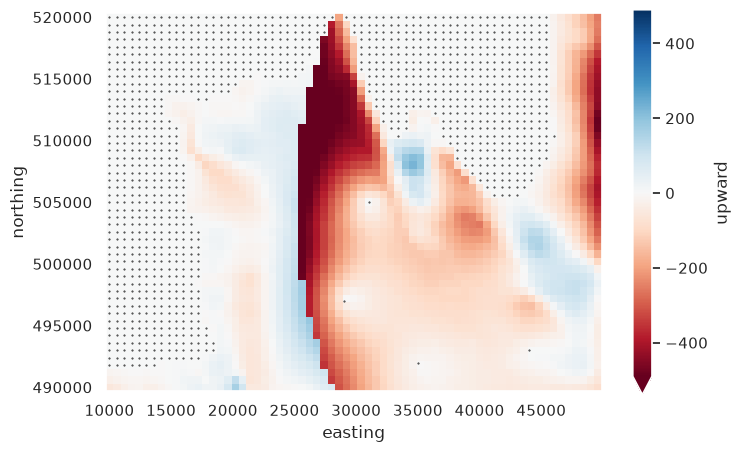

In [17]:
ax = (
    (true_basement - starting_topography.upward)
    .plot(figsize=(8, 5), cmap="RdBu", center=0, robust=True)
    .axes
)
constraint_points.plot.scatter("easting", "northing", ax=ax, c="k", s=0.2)
ax.set_aspect("equal")

## Forward calculate the observed gravity

The observed gravity is the effect of the true basement surface (relative to the reference level) at a constant observation height of 2200 m, just above the highest topography, contaminated with 0.15 mGal of Gaussian noise.

In practice this corresponds to gravity data which have already been corrected for any deeper regional sources and for the terrain: the effect of all known material between the ground surface and the reference level — basement at the outcrops, sediment plus basement within the basin — computed as if it were all at basement density.
What such a correction leaves behind is exactly the effect of having basement density replaced by sediment density beneath the covered areas, which is what our prism model with its constant 400 kg/m$^3$ contrast represents.
This is why the model needs no knowledge of absolute rock densities, only of the sediment-basement contrast.

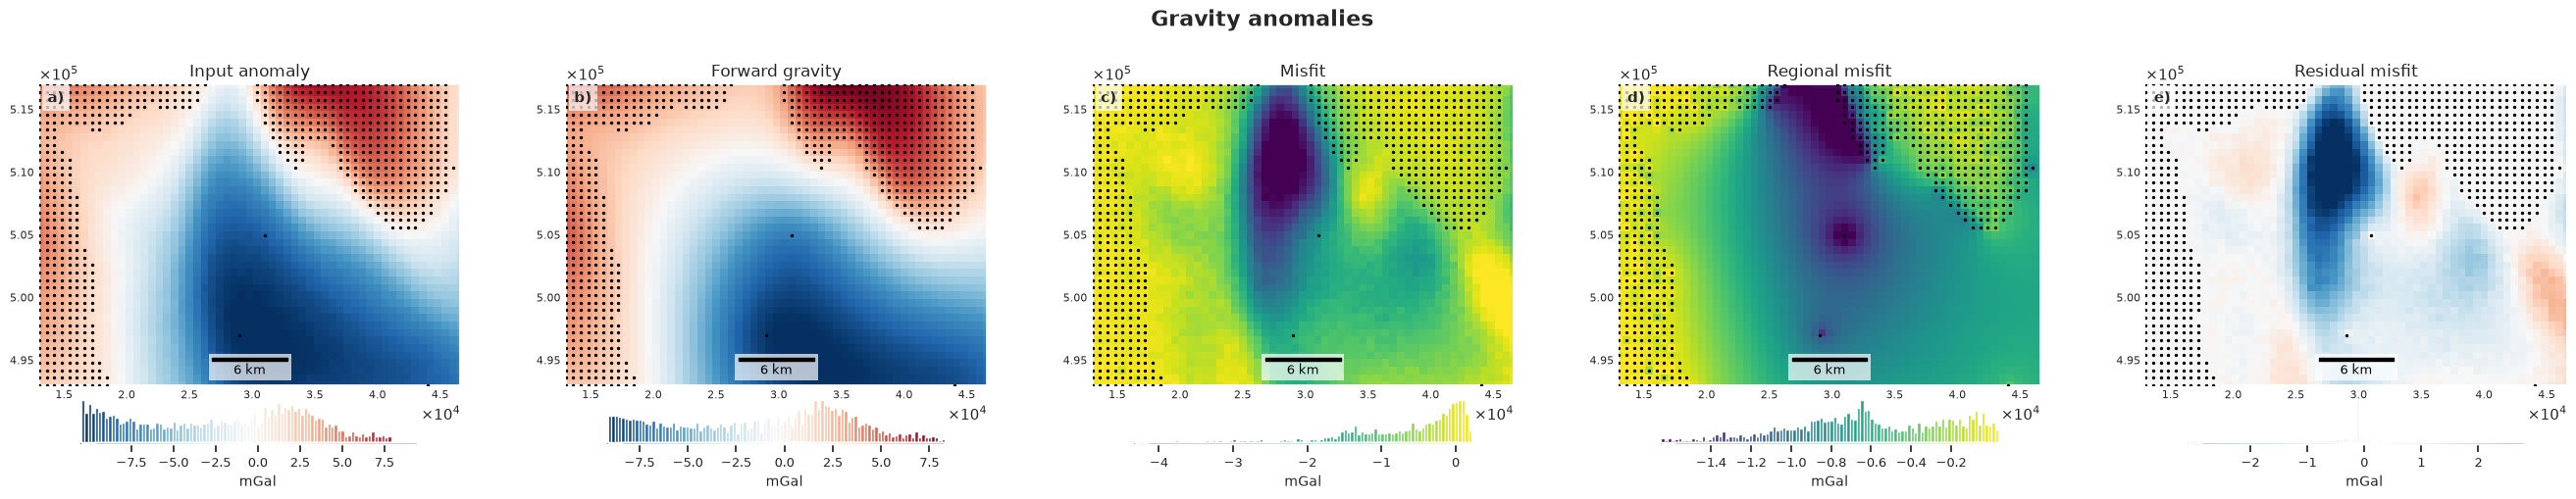

In [18]:
observed_gravity = vd.make_xarray_grid(
    (easting2d, northing2d),
    data=(np.zeros_like(easting2d), np.full_like(easting2d, 2200.0)),
    data_names=("gravity_anomaly", "upward"),
)

# remove gravity data points over outcropping basement
observed_gravity["mask"] = grav_mask

data = invert4geom.create_data(observed_gravity)

# forward gravity of the true model
data.inv.forward_gravity(true_model, progressbar=False)

# contaminate with noise and use as the observed gravity
# (keep the noise-free version so we can add other noise realizations later)
gravity_noise = 0.05
noise_free_gravity = data.forward_gravity.copy()
data["gravity_anomaly"], _ = invert4geom.synthetic.contaminate(
    noise_free_gravity,
    stddev=gravity_noise,
    seed=0,
)

# gravity misfit of the starting model
data.inv.forward_gravity(starting_model, progressbar=False)
regional_separation_kwargs = dict(
    method="constraints",
    grid_method="pygmt",
    grid_points_col="grid_points",
    tension=1,
    constraints_df=constraint_points,
)
data.inv.regional_separation(**regional_separation_kwargs)

data.inv.plot_anomalies(points=constraint_points, points_style="c.1c")

## Weighting grid

To keep the inversion from changing the basement where it is already known, we damp the corrections by the normalized distance to the nearest constraint, computed with [normalized_mindist](../api/generated/invert4geom.normalized_mindist.rst): corrections are multiplied by 0 at the constraints, ramping up to 1 far from them, so the inversion only alters the model in the data gaps between outcrops and boreholes.

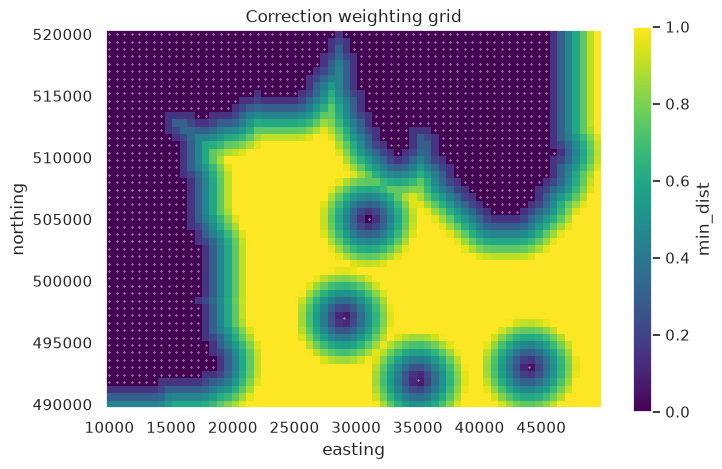

In [19]:
weighting_grid = invert4geom.normalized_mindist(
    constraint_points,
    starting_model.starting_topography,
    low=0,
    high=1,
    maxdist=4e3,
)

ax = weighting_grid.plot(figsize=(8, 5), cmap="viridis").axes
constraint_points.plot.scatter(
    "easting",
    "northing",
    s=0.1,
    ax=ax,
    c="white",
)
plt.gca().set_aspect("equal")
plt.title("Correction weighting grid")
plt.show()

## The inversions

We now invert the same gravity data five ways and compare them. Two are the
baselines above — the smooth **L2** and sharp **L1** solvers, which recover the
fault only implicitly. The other method uses the **known fault trace** directly, by letting the surface step freely across the trace. This is referred to as a *fault-aware regularization**.

Each produces a recovered basement `topo_*`; we compare the surfaces, then the
per-method uncertainty.

In [20]:
inv_kwargs = dict(
    data=copy.deepcopy(data),
    model=copy.deepcopy(starting_model),
    max_iterations=30,
    l2_norm_tolerance=np.sqrt(gravity_noise),
    delta_l2_norm_tolerance=1.001,
    weighting_grid=weighting_grid,
    apply_weighting_grid=True,
)

### Smooth inversion (L2-norm)

We stop the inversion at the noise floor and use cross validation of the gravity data to find the optimal damping value.

  0%|          | 0/4 [00:00<?, ?it/s]

Inversion terminated due to max_iterations limit. Consider increasing this limit.


  0%|          | 0/4 [00:00<?, ?it/s]

Inversion terminated due to max_iterations limit. Consider increasing this limit.


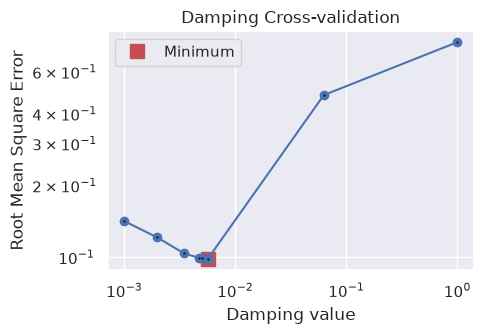

In [21]:
inv_l2 = invert4geom.Inversion(**inv_kwargs)

# resample data at 1/2 spacing to include test points for cross-validation
inv_l2.data = invert4geom.add_test_points(inv_l2.data)

damping_cv_obj = inv_l2.optimize_inversion_damping(
    damping_limits=(0.001, 1),
    n_trials=8,
    fname="../tmp/fault_bounded_basin_damping_CV",
)

In [22]:
damping_cv_obj.study.trials_dataframe().sort_values("value").head()

,number,value,datetime_start,datetime_complete,duration,params_damping,user_attrs_fname,system_attrs_fixed_params,system_attrs_gp:relative_params:0,state
7,7,0.098676,2026-10-16 18:35:51.142041,2026-10-16 18:36:54.892756,0 days 00:01:03.750715,0.005670,../tmp/fault_bounded_basin_damping_CV_trial_7,NaN,"{""damping"": 0.00566975218886233}",COMPLETE
5,5,0.099050,2026-10-16 18:33:52.646798,2026-10-16 18:34:52.381799,0 days 00:00:59.735001,0.005013,../tmp/fault_bounded_basin_damping_CV_trial_5,NaN,"{""damping"": 0.005013191817044792}",COMPLETE
6,6,0.099446,2026-10-16 18:34:52.383816,2026-10-16 18:35:51.140946,0 days 00:00:58.757130,0.004722,../tmp/fault_bounded_basin_damping_CV_trial_6,NaN,"{""damping"": 0.0047222552621875025}",COMPLETE
4,4,0.104167,2026-10-16 18:33:09.187114,2026-10-16 18:33:52.645443,0 days 00:00:43.458329,0.003438,../tmp/fault_bounded_basin_damping_CV_trial_4,NaN,"{""damping"": 0.003438211992388531}",COMPLETE
2,2,0.121272,2026-10-16 18:31:51.496874,2026-10-16 18:32:07.252032,0 days 00:00:15.755158,0.001983,../tmp/fault_bounded_basin_damping_CV_trial_2,NaN,NaN,COMPLETE


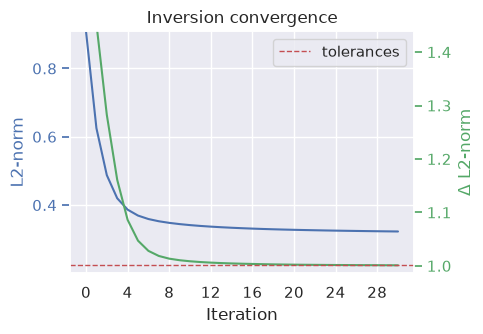

In [23]:
inv_l2.plot_convergence()
topo_l2 = inv_l2.model.topography

In [24]:
starting_model

<xarray.Dataset> Size: 247kB
Dimensions:                (northing: 51, easting: 67)
Coordinates:
  * northing               (northing) float64 408B 4.9e+05 4.906e+05 ... 5.2e+05
  * easting                (easting) float64 536B 1e+04 1.06e+04 ... 4.96e+04
    top                    (northing, easting) float64 27kB 767.9 ... 800.0
    bottom                 (northing, easting) float64 27kB 642.3 ... 642.3
Data variables:
    density                (northing, easting) int64 27kB 400 400 ... 400 400
    thickness              (northing, easting) float64 27kB 125.6 ... 157.7
    starting_topography    (northing, easting) float64 27kB 767.9 ... 800.0
    topography             (northing, easting) float64 27kB 767.9 ... 800.0
    mask                   (northing, easting) float64 27kB 1.0 1.0 ... 1.0 1.0
    upper_confining_layer  (northing, easting) float64 27kB 800.0 ... 800.0
    lower_confining_layer  (northing, easting) float64 27kB nan nan ... nan nan
Attributes:
    zref:              642.2558789550931
    density_contrast:  400
    region:            (10000.0, 49600.0, 490000.0, 520000.0)
    spacing:           600.0
    buffer_width:      0
    inner_region:      (10000.0, 49600.0, 490000.0, 520000.0)
    dataset_type:      model
    model_type:        prisms
    coord_names:       ('easting', 'northing')

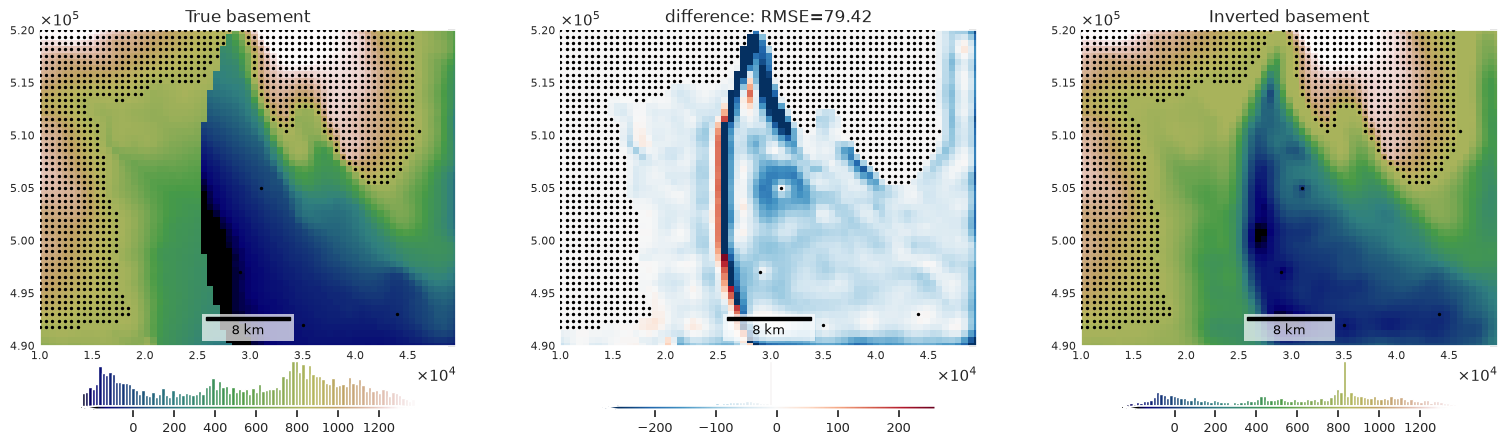

In [25]:
_ = invert4geom.grid_compare(
    true_basement,
    topo_l2,
    grid1_name="True basement",
    grid2_name="Inverted basement",
    robust=True,
    hist=True,
    inset=False,
    title="difference",
    cmap="gist_earth",
    points=constraint_points,
    points_style="c.1c",
)

### Sharp inversion (IRLS, L1-norm)

The same inversion with the IRLS solver and a cross validation to find the optimal `sharpness_weight`.
The L1-norm gradient penalty does not force the whole model to be blocky; it concentrates the model's gradients into as few, large steps as the data allow, so the smoothly varying deeper parts of the basin can coexist with a sharp step at the buried fault.

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

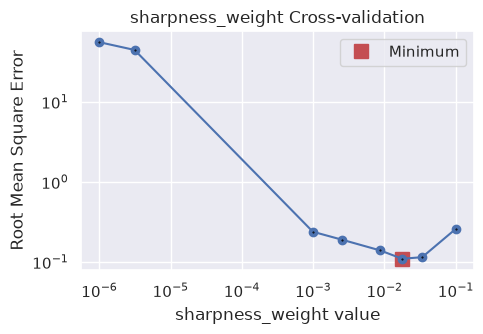

In [26]:
inv_l1 = invert4geom.Inversion(
    solver_type="irls",
    sharpness_weight=0.01,
    **inv_kwargs,
)

# resample data at 1/2 spacing to include test points for cross-validation
inv_l1.data = invert4geom.add_test_points(inv_l1.data)

sharpness_cv_obj = inv_l1.optimize_inversion_sharpness(
    sharpness_weight_limits=(1e-6, 1e-1),
    n_trials=8,
    fname="../tmp/fault_bounded_basin_sharpness_CV",
)

In [27]:
sharpness_cv_obj.study.trials_dataframe().sort_values("value").head()

,number,value,datetime_start,datetime_complete,duration,params_sharpness_weight,user_attrs_fname,system_attrs_fixed_params,system_attrs_gp:relative_params:0,state
7,7,0.109912,2026-10-16 18:48:59.682508,2026-10-16 18:51:04.183619,0 days 00:02:04.501111,0.017689,../tmp/fault_bounded_basin_sharpness_CV_trial_7,NaN,"{""sharpness_weight"": 0.017689096281057783}",COMPLETE
6,6,0.114923,2026-10-16 18:46:49.476017,2026-10-16 18:48:59.681328,0 days 00:02:10.205311,0.033757,../tmp/fault_bounded_basin_sharpness_CV_trial_6,NaN,"{""sharpness_weight"": 0.0337566233506852}",COMPLETE
4,4,0.139478,2026-10-16 18:45:53.542037,2026-10-16 18:46:25.274869,0 days 00:00:31.732832,0.008743,../tmp/fault_bounded_basin_sharpness_CV_trial_4,NaN,"{""sharpness_weight"": 0.008743265904243427}",COMPLETE
5,5,0.190245,2026-10-16 18:46:25.276234,2026-10-16 18:46:49.474570,0 days 00:00:24.198336,0.002527,../tmp/fault_bounded_basin_sharpness_CV_trial_5,NaN,"{""sharpness_weight"": 0.0025267915735628158}",COMPLETE
3,3,0.238890,2026-10-16 18:45:21.796382,2026-10-16 18:45:53.526068,0 days 00:00:31.729686,0.000990,../tmp/fault_bounded_basin_sharpness_CV_trial_3,NaN,NaN,COMPLETE


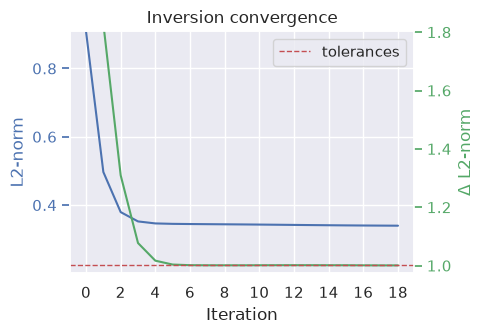

In [28]:
inv_l1.plot_convergence()
topo_l1 = inv_l1.model.topography

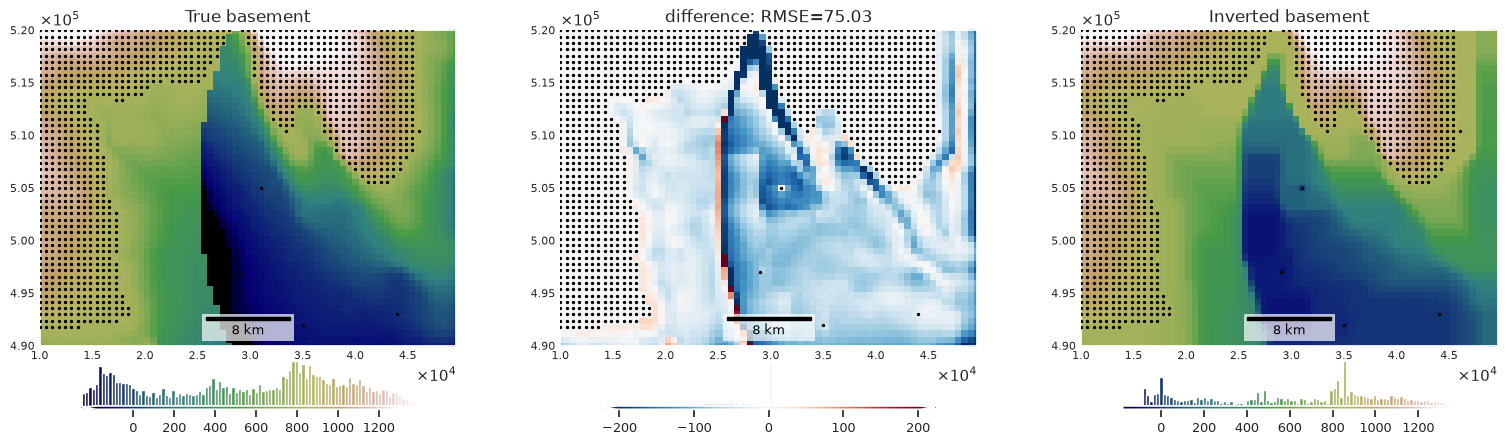

In [29]:
_ = invert4geom.grid_compare(
    true_basement,
    topo_l1,
    grid1_name="True basement",
    grid2_name="Inverted basement",
    robust=True,
    hist=True,
    inset=False,
    title="difference",
    cmap="gist_earth",
    points=constraint_points,
    points_style="c.1c",
)

### Fault-aware regularization

The IRLS solver's sharpness penalty couples every model cell to its eastern and
northern neighbour through a first-difference gradient operator. A fault is exactly
where neighbours should *not* be coupled. Passing the trace vertices as
`fault_trace` drops the operator rows whose cell pair straddles the fault, so the
surface is free to **step across the fault** while staying coherent within each
block. Everything else is identical to the L1 inversion above.

Here the trace we supply is the one used to build the synthetic basement, i.e. it is
known exactly. In practice it would come from mapping or from the gravity gradient,
and the recovered step will only be as well located as that trace.

In [30]:
def points_to_mask(coordinates, grid):
    """1 at the grid cell nearest each point, NaN everywhere else."""
    e, n = grid.easting.values, grid.northing.values
    j = np.abs(e[:, None] - coordinates[0]).argmin(axis=0)
    i = np.abs(n[:, None] - coordinates[1]).argmin(axis=0)
    mask = np.full(grid.shape, np.nan)
    mask[i, j] = 1
    return xr.DataArray(mask, coords=grid.coords, dims=grid.dims, name="mask")

<Axes: xlabel='easting', ylabel='northing'>

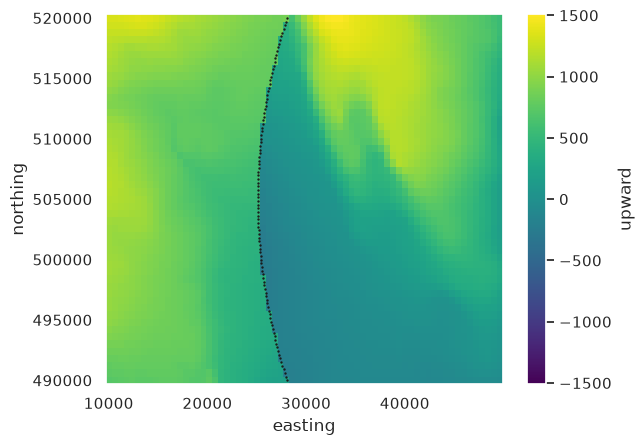

In [31]:
# convert fault trace to mask
fault_mask = points_to_mask(
    (fault_trace_vertices.easting.values, fault_trace_vertices.northing.values),
    xr.ones_like(true_basement),
)

# expand the mask by several grid cells for to create a mask for the gravity data
fault_mask = invert4geom.buffer_edges(fault_mask, cells=1, grow=True)


# fault_trace_points = vd.grid_to_table(fault_mask).dropna()[['easting','northing']]
fault_trace_points = fault_trace_vertices

ax = true_basement.plot(cmap="viridis").axes

fault_trace_points.plot.scatter(
    "easting",
    "northing",
    ax=ax,
    c="k",
    s=0.5,
)

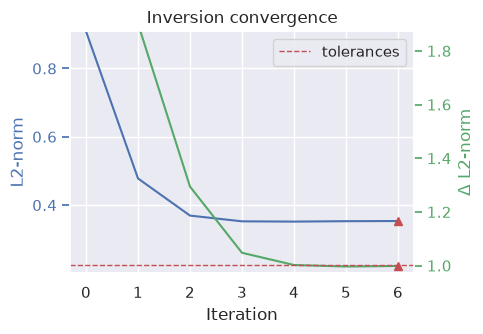

excluded 53 cell pairs which cross the fault trace


In [32]:
inv_fault = invert4geom.Inversion(
    fault_trace=fault_trace_points,
    solver_type="irls",
    sharpness_weight=inv_l1.sharpness_weight,
    **inv_kwargs,
)

inv_fault.invert(
    plot_dynamic_convergence=True,
)
topo_fault = inv_fault.model.topography
print(f"excluded {inv_fault.n_cut_edges} cell pairs which cross the fault trace")

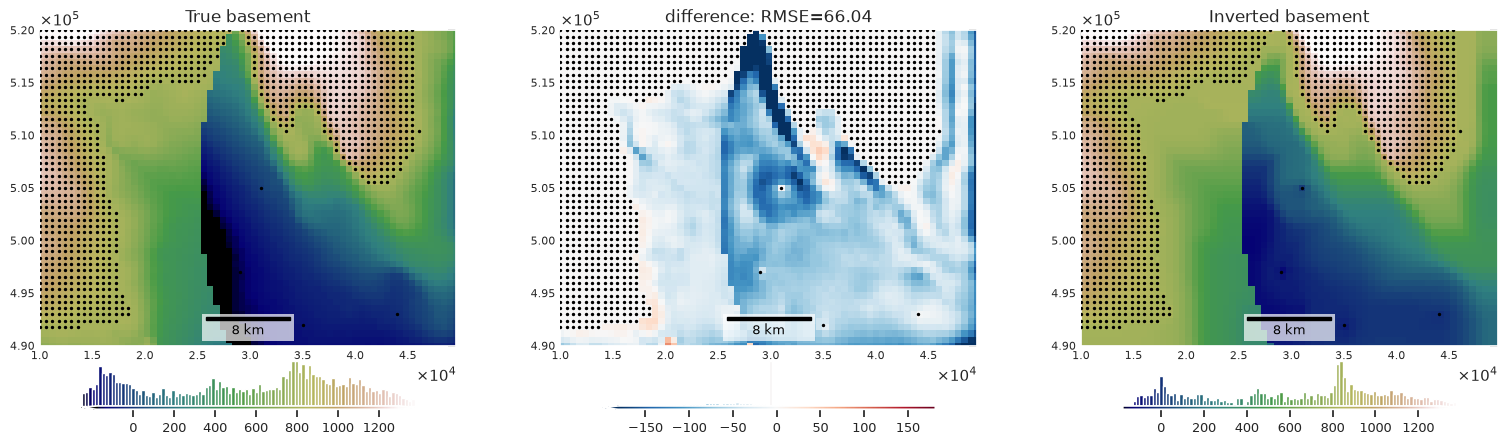

In [33]:
_ = invert4geom.grid_compare(
    true_basement,
    topo_fault,
    grid1_name="True basement",
    grid2_name="Inverted basement",
    robust=True,
    hist=True,
    inset=False,
    title="difference",
    cmap="gist_earth",
    points=constraint_points,
    points_style="c.1c",
)

## Compare the recovered surfaces

All five inversions of the *same* gravity, against the true basement — as maps
with their error, and along the basin-center profile.

In [34]:
constraint_points

,easting,northing,upward,grid_points
0,10000.0,491800.0,808.000000,True
1,10600.0,491800.0,811.000000,True
2,11200.0,491800.0,814.000000,True
3,11800.0,491800.0,814.000000,True
4,12400.0,491800.0,812.000000,True
...,...,...,...,...
1209,45400.0,520000.0,806.905637,True
1210,29000.0,497000.0,-153.914595,False
1211,31000.0,505000.0,22.875660,False
1212,35000.0,492000.0,-84.676111,False


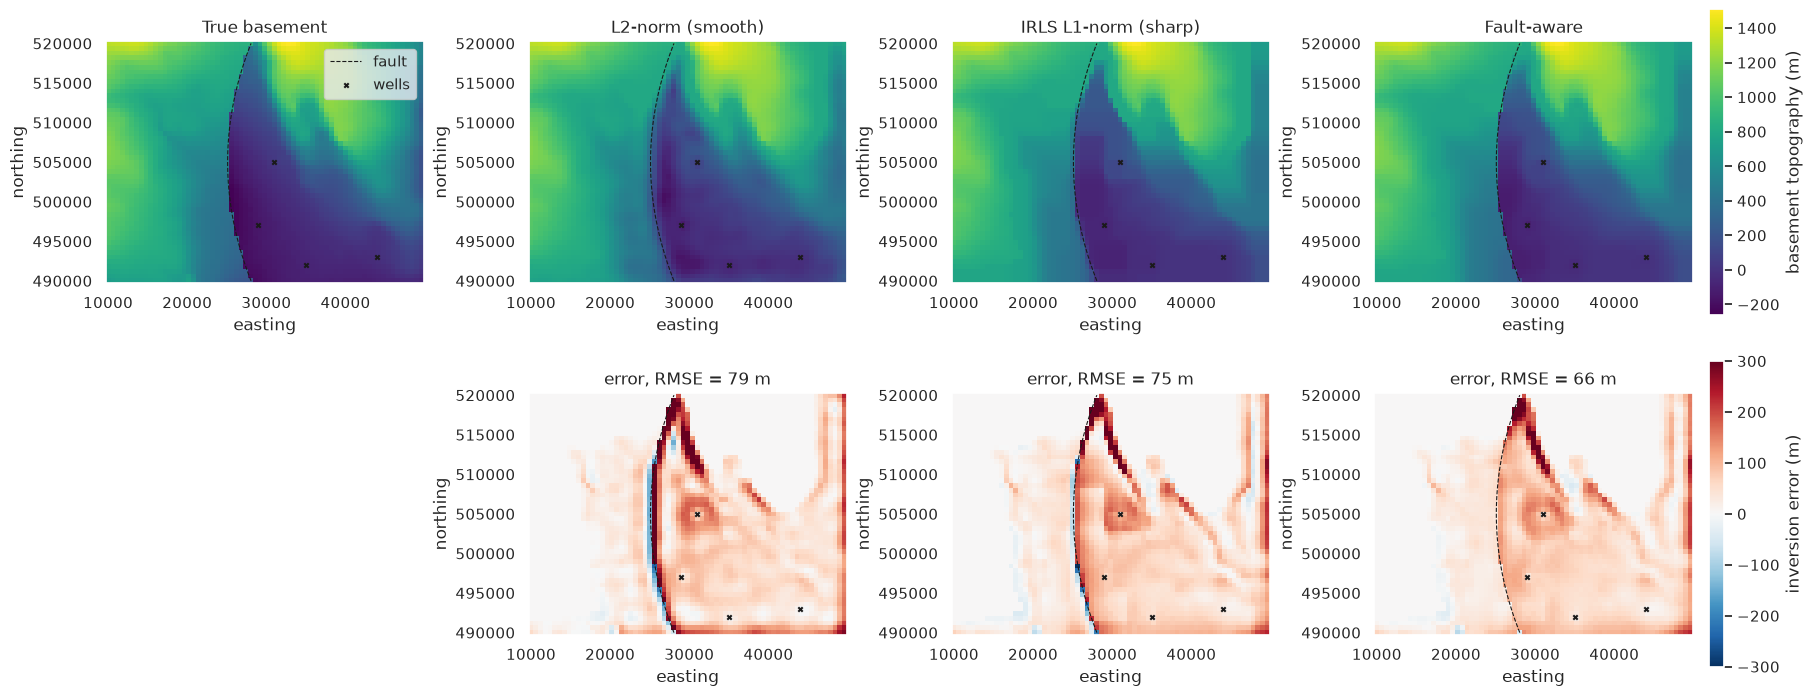

In [35]:
methods = [
    ("L2-norm (smooth)", topo_l2),
    ("IRLS L1-norm (sharp)", topo_l1),
    ("Fault-aware", topo_fault),
]
vmin, vmax = float(true_basement.min()), float(true_basement.max())
fig, axes = plt.subplots(2, 4, figsize=(18, 7), constrained_layout=True)
true_basement.plot(
    ax=axes[0, 0],
    vmin=vmin,
    vmax=vmax,
    cmap="viridis",
    add_colorbar=False,
)
axes[0, 0].set_ylabel("northing")
axes[0, 0].set_xlabel("easting")
axes[0, 0].set_title("True basement")
axes[1, 0].axis("off")
for k, (name, topo) in enumerate(methods):
    im_topo = topo.plot(
        ax=axes[0, k + 1], vmin=vmin, vmax=vmax, cmap="viridis", add_colorbar=False
    )
    axes[0, k + 1].set_title(name)
    im_error = (topo - true_basement).plot(
        ax=axes[1, k + 1], vmin=-300, vmax=300, cmap="RdBu_r", add_colorbar=False
    )
    axes[1, k + 1].set_title(
        f"error, RMSE = {invert4geom.rmse(topo - true_basement):.0f} m"
    )

fig.colorbar(im_topo, ax=axes[0, 3], label="basement topography (m)")
fig.colorbar(im_error, ax=axes[1, 3], label="inversion error (m)")

for i, ax in enumerate(axes.ravel()):
    if i == 0:
        label1 = "fault"
        label2 = "wells"
    else:
        label1, label2 = None, None
    if ax.has_data():
        ax.plot(
            fault_trace(trace_northing),
            trace_northing,
            "k--",
            lw=0.8,
            label=label1,
        )
        constraint_points[~constraint_points.grid_points].plot.scatter(
            "easting", "northing", ax=ax, s=10, marker="x", c="k", label=label2
        )
        ax.set_aspect("equal")
    if i == 0:
        ax.legend()
plt.show()

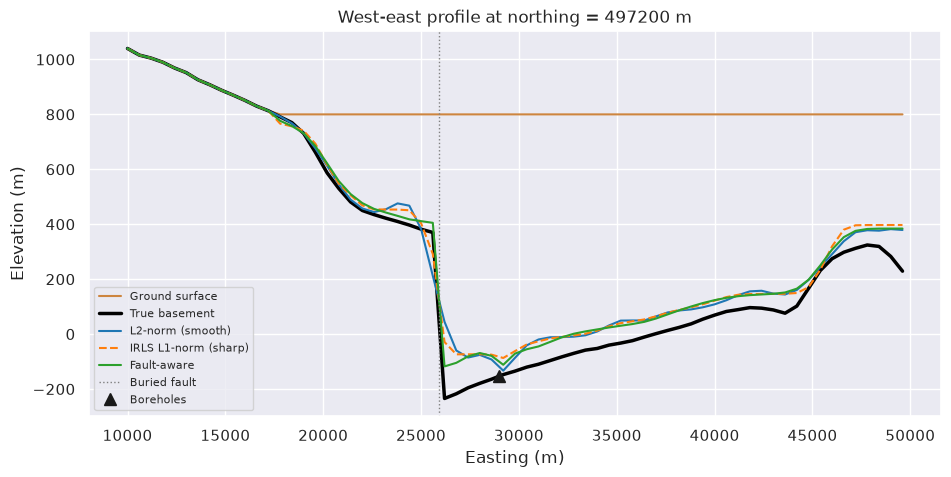

In [36]:
fig, ax = plt.subplots(figsize=(11, 5))
surface.sel(northing=profile_northing).plot(
    ax=ax, color="peru", lw=1.5, label="Ground surface"
)
true_basement.sel(northing=profile_northing).plot(
    ax=ax, color="black", lw=2.5, label="True basement"
)
for name, topo, style, c in [
    ("L2-norm (smooth)", topo_l2, "-", "tab:blue"),
    ("IRLS L1-norm (sharp)", topo_l1, "--", "tab:orange"),
    ("Fault-aware", topo_fault, "-", "tab:green"),
]:
    topo.sel(northing=profile_northing).plot(
        ax=ax, lw=1.5, ls=style, color=c, label=name
    )
ax.axvline(
    fault_trace(profile_northing), color="gray", ls=":", lw=1, label="Buried fault"
)
on_profile = boreholes[np.abs(boreholes.northing - profile_northing) <= 1000]
ax.plot(
    on_profile.easting,
    on_profile.upward,
    "^",
    color="k",
    markersize=9,
    label="Boreholes",
)
ax.set_title(f"West-east profile at northing = {profile_northing:.0f} m")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Elevation (m)")
ax.legend(fontsize=8)
plt.show()

## Uncertainty analysis for each method

For every method we repeat the inversion over five noise realizations of the
observed gravity and turn the ensemble into two deliverables: a **fault-location
(scarp) probability** map, and the **along-strike throw** with a ±2σ envelope. The
two full-inversion baselines and the fault-aware method re-run the inversion per
realization.

In [37]:
n_runs = 5

new_inv_kwargs = copy.deepcopy(inv_kwargs)
new_inv_kwargs.pop("data")


def inversion_ensemble(**kwargs):
    """repeat a full inversion over noise realizations of the observed gravity"""
    topographies = []
    for seed in tqdm(range(n_runs), desc="inversion ensemble"):
        run_data = copy.deepcopy(data)
        run_data["gravity_anomaly"], _ = invert4geom.synthetic.contaminate(
            noise_free_gravity, stddev=gravity_noise, seed=seed
        )
        run_data.inv.regional_separation(**regional_separation_kwargs)
        inv = invert4geom.Inversion(
            run_data,
            **kwargs,
            **new_inv_kwargs,
        )
        inv.invert(progressbar=False)
        topographies.append(inv.model.topography)
    return invert4geom.uncertainty.merge_simulation_results(topographies)


ensembles = {
    "L2-norm (smooth)": inversion_ensemble(
        solver_damping=inv_l2.solver_damping,
    ),
    "IRLS L1-norm (sharp)": inversion_ensemble(
        solver_type="irls",
        sharpness_weight=inv_l1.sharpness_weight,
    ),
    "Fault-aware": inversion_ensemble(
        fault_trace=fault_trace_points,
        solver_type="irls",
        sharpness_weight=inv_fault.sharpness_weight,
    ),
}
print(f"built ensembles for {len(ensembles)} methods, {n_runs} runs each")

inversion ensemble:   0%|          | 0/5 [00:00<?, ?it/s]

Inversion terminated due to max_iterations limit. Consider increasing this limit.


Inversion terminated due to max_iterations limit. Consider increasing this limit.


Inversion terminated due to max_iterations limit. Consider increasing this limit.


Inversion terminated due to max_iterations limit. Consider increasing this limit.


...

Inversion terminated due to max_iterations limit. Consider increasing this limit.


Inversion terminated due to max_iterations limit. Consider increasing this limit.


Inversion terminated due to max_iterations limit. Consider increasing this limit.


inversion ensemble:   0%|          | 0/5 [00:00<?, ?it/s]

built ensembles for 3 methods, 5 runs each


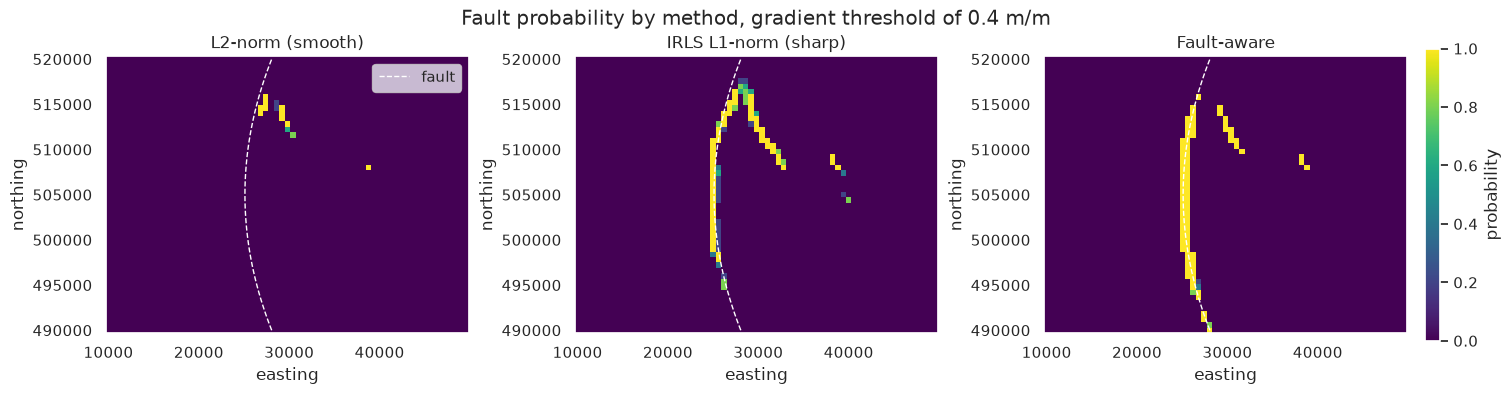

In [38]:
threshold = 0.4  # gradient magnitude (m/m) above which a cell counts as a scarp
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
for ax, (name, ensemble) in zip(axes, ensembles.items()):
    stats = invert4geom.uncertainty.topography_gradient_uncertainty(
        ensemble, threshold=threshold
    )
    im = stats.scarp_probability.plot(
        ax=ax, vmin=0, vmax=1, cmap="viridis", add_colorbar=False
    )
    ax.plot(fault_trace(trace_northing), trace_northing, "w--", lw=1, label="fault")
    ax.set_aspect("equal")
    ax.set_title(name)
fig.suptitle(f"Fault probability by method, gradient threshold of {threshold} m/m")
fig.colorbar(im, ax=ax, label="probability")
axes[0].legend()
plt.show()

In [39]:
offsets = np.linspace(spacing, spacing * 2, 6)
offsets

array([ 600.,  720.,  840.,  960., 1080., 1200.])

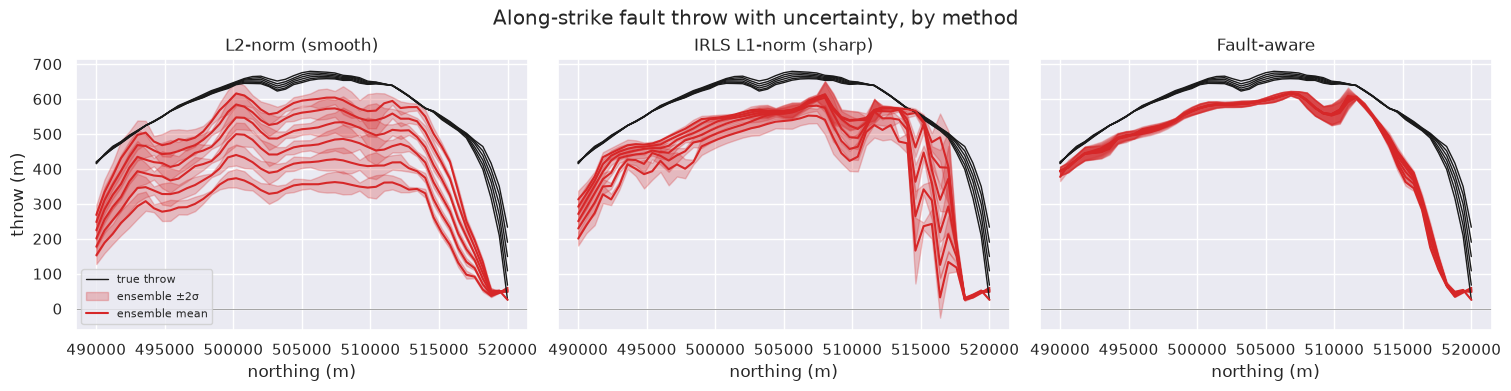

In [40]:
northings = surface.northing.values
nd = xr.DataArray(northings, dims="northing", coords={"northing": surface.northing})

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True, constrained_layout=True)
for ax, (name, ensemble) in zip(axes, ensembles.items()):
    for i, o in enumerate(offsets):
        west = xr.DataArray(fault_trace(northings) - o, dims="northing")
        east = xr.DataArray(fault_trace(northings) + o, dims="northing")
        true_throw = (
            true_basement.interp(easting=west, northing=nd)
            - true_basement.interp(easting=east, northing=nd)
        ).values
        throws = xr.concat(
            [
                (
                    ensemble[r].interp(easting=west, northing=nd)
                    - ensemble[r].interp(easting=east, northing=nd)
                ).rename(r)
                for r in ensemble
            ],
            dim="runs",
        )
        mean, std = throws.mean("runs"), throws.std("runs")

        if i == 0:
            label1 = "true throw"
            label2 = "ensemble ±2σ"
            label3 = "ensemble mean"

        else:
            label1, label2, label3 = None, None, None
        ax.plot(northings, true_throw, "k", lw=1, label=label1)

        ax.fill_between(
            northings,
            mean - 2 * std,
            mean + 2 * std,
            color="tab:red",
            alpha=0.25,
            label=label2,
        )
        ax.plot(northings, mean, color="tab:red", lw=1.5, label=label3)
    ax.axhline(0, color="gray", lw=0.5)
    ax.set_title(name)
    ax.set_xlabel("northing (m)")
axes[0].set_ylabel("throw (m)")
axes[0].legend(fontsize=8)
fig.suptitle("Along-strike fault throw with uncertainty, by method")
plt.show()

Reading across the methods: **fault-aware regularization** gives the best surface
(lowest RMSE) and the tightest, best-located scarp-probability band, because it is
the only method that recovers the sharp offset *and* fits the data fully. **L2**
smears the scarp (diffuse probability, under-read throw); **L1** sharpens it.

## Final thoughts

This scenario shows how the pieces of *Invert4Geom* fit together for a realistic basin problem:

- **The fault can enter the inversion implicitly or explicitly.** The smooth (L2) and sharp (L1) solvers recover it as a feature of a per-cell surface; the fault-aware regularization use the known trace directly. Fault-aware regularization gives the best surface here.
- **Hard data can enter several ways**: constraint points build the starting model, the ground surface is an upper confining layer, and the constraints are enforced with a weighting grid, by masking, via a constraint-point regional, or by weighting the residual.
- **Every method carries an uncertainty**: a noise-realization ensemble turns each into a fault-location probability map and an along-strike throw with error bars.
- A **gradient-based scarp detector** flags every steep feature, including genuinely steep outcropping basement topography; the interpretation step separates those known features from the newly imaged buried fault.

In [41]:
# # trial 1: no weighting grid, regional field estimated from the constraint points
# model_regional = invert4geom.create_model(
#     zref=zref,
#     density_contrast=density_contrast,
#     topography=starting_topography,
#     upper_confining_layer=surface,
# )
# data_regional = copy.deepcopy(data)
# data_regional.inv.forward_gravity(model_regional, progressbar=False)
# data_regional.inv.regional_separation(
#     method="constraints",
#     constraints_df=constraint_points,
#     grid_method="verde",
#     spline_dampings=[None, 0.001, 0.1],
# )
# data_regional.inv.plot_anomalies(points=constraint_points, points_style="p.1")

In [42]:
# inv_regional = invert4geom.Inversion(
#     data_regional,
#     model_regional,
#     solver_type="irls",
#     sharpness_weight=0.01,
#     max_iterations=100,
#     l2_norm_tolerance=np.sqrt(gravity_noise),
#     delta_l2_norm_tolerance=1.001,
# )
# inv_regional.invert(progressbar=False)
# inv_regional.termination_reason

In [43]:
# # trial 2: mask the model cells which are constraints
# masked_topography = starting_topography.copy()
# distance_to_constraint = invert4geom.normalized_mindist(
#     constraint_points,
#     starting_topography.upward,
# )
# masked_topography["mask"] = xr.where(distance_to_constraint < spacing, np.nan, 1)

# model_masked = invert4geom.create_model(
#     zref=zref,
#     density_contrast=density_contrast,
#     topography=masked_topography,
#     upper_confining_layer=surface,
# )

# model_masked.mask.plot(cmap="viridis", add_colorbar=False)
# plt.title("Model mask (blank = constrained cells, excluded)")

# data_masked = copy.deepcopy(data)
# data_masked.inv.forward_gravity(model_masked, progressbar=False)
# data_masked.inv.regional_separation(method="constant", constant=0)

# data_masked.inv.plot_anomalies(points=constraint_points, points_style="p.1")

In [44]:
# inv_masked = invert4geom.Inversion(
#     data_masked,
#     model_masked,
#     solver_type="irls",
#     sharpness_weight=0.01,
#     max_iterations=100,
#     l2_norm_tolerance=np.sqrt(gravity_noise),
#     delta_l2_norm_tolerance=1.001,
# )
# inv_masked.invert(progressbar=False)
# inv_masked.termination_reason

In [45]:
# # trial 3: weight the residual instead of the corrections
# model_res_weighted = invert4geom.create_model(
#     zref=zref,
#     density_contrast=density_contrast,
#     topography=starting_topography,
#     upper_confining_layer=surface,
# )
# data_res_weighted = copy.deepcopy(data)
# data_res_weighted.inv.forward_gravity(model_res_weighted, progressbar=False)
# data_res_weighted.inv.regional_separation(method="constant", constant=0)

# data_res_weighted.inv.plot_anomalies(points=constraint_points, points_style="p.1")

In [46]:
# starting_topography.upward.plot()

In [47]:
# inv_res_weighted = invert4geom.Inversion(
#     data_res_weighted,
#     model_res_weighted,
#     solver_type="irls",
#     sharpness_weight=0.01,
#     apply_residual_weighting_grid=True,
#     residual_weighting_grid=weighting_grid,
#     max_iterations=100,
#     l2_norm_tolerance=np.sqrt(gravity_noise),
#     delta_l2_norm_tolerance=1.001,
# )
# inv_res_weighted.invert(progressbar=False)
# inv_res_weighted.termination_reason

In [48]:
# # trial 4: weighting grid and constraint point minimization
# model_regional_weighting = invert4geom.create_model(
#     zref=zref,
#     density_contrast=density_contrast,
#     topography=starting_topography,
#     upper_confining_layer=surface,
# )
# data_regional_weighting = copy.deepcopy(data)
# data_regional_weighting.inv.forward_gravity(model_regional_weighting, progressbar=False)
# data_regional_weighting.inv.regional_separation(
#     method="constraints",
#     constraints_df=constraint_points,
#     grid_method="verde",
#     spline_dampings=[None, 0.001, 0.1],
# )
# data_regional_weighting.inv.plot_anomalies(points=constraint_points, points_style="p.1")

In [49]:
# inv_regional_weighting = invert4geom.Inversion(
#     data_regional_weighting,
#     model_regional_weighting,
#     solver_type="irls",
#     sharpness_weight=0.01,
#     max_iterations=100,
#     l2_norm_tolerance=np.sqrt(gravity_noise),
#     delta_l2_norm_tolerance=1.001,
#     apply_weighting_grid=True,
#     weighting_grid=weighting_grid,
# )
# inv_regional_weighting.invert(progressbar=False)
# inv_regional_weighting.termination_reason

In [50]:
# topo_regional = inv_regional.model.topography
# topo_masked = inv_masked.model.topography
# topo_res_weighted = inv_res_weighted.model.topography
# topo_regional_weighting = inv_regional_weighting.model.topography

# strategies = {
#     "Weighting grid": topo_l1,
#     "Constraints regional": topo_regional,
#     "Weighting grid and constraint point minimization": topo_regional_weighting,
#     "Masked constraints": topo_masked,
#     "Residual weighting": topo_res_weighted,
# }

# fig, axes = plt.subplots(
#     1, 2, figsize=(16, 5), constrained_layout=True, width_ratios=[1.3, 1]
# )

# ax = axes[0]
# true_basement.sel(northing=profile_northing).plot(
#     ax=ax, color="black", lw=2, label="True basement"
# )
# colors = ["tab:red", "tab:purple", "tab:orange", "tab:green", "tab:blue"]
# for (name, topo), color in zip(strategies.items(), colors, strict=True):
#     rmse = float(np.sqrt(np.mean((topo.values - true_basement.values) ** 2)))
#     topo.sel(northing=profile_northing).plot(
#         ax=ax, color=color, lw=1.5, label=f"{name} (RMSE = {rmse:.0f} m)"
#     )
# ax.axvline(fault_trace(profile_northing), color="gray", ls=":", lw=1)

# # boreholes within 1 km of the profile
# on_profile = boreholes[np.abs(boreholes.northing - profile_northing) <= 1000]
# ax.plot(
#     on_profile.easting,
#     on_profile.upward,
#     "^",
#     color="red",
#     markersize=9,
#     label="Boreholes",
# )

# ax.set_title(f"IRLS inversions, profile at northing = {profile_northing:.0f} m")
# ax.set_xlabel("Easting (m)")
# ax.set_ylabel("Elevation (m)")
# ax.legend()

# ax = axes[1]
# (topo_regional - true_basement).plot(ax=ax, vmin=-300, vmax=300, cmap="RdBu_r")
# ax.set_aspect("equal")
# ax.set_title("Constraints regional: error")

# plt.show()

In [51]:
# # RMS error of each method against the true basement, over the whole grid and at
# # the well (borehole) sites
# rms_rows = {}
# for name, topo in strategies.items():
#     grid_rms = float(np.sqrt(np.mean((topo.values - true_basement.values) ** 2)))
#     wells = invert4geom.sample_grids(
#         boreholes[["easting", "northing", "upward"]].copy(),
#         topo,
#         sampled_name="predicted",
#     )
#     well_rms = float(np.sqrt(np.mean((wells.predicted - wells.upward) ** 2)))
#     rms_rows[name] = {
#         "Whole grid RMS (m)": grid_rms,
#         "Well sites RMS (m)": well_rms,
#     }

# rms_df = pd.DataFrame(rms_rows).T

# rms_df = rms_df.sort_values(["Whole grid RMS (m)", "Well sites RMS (m)"])
# rms_df.round(1)

In [52]:
# # plot the RMS errors of each method
# fig, ax = plt.subplots(figsize=(9, 4))
# rms_df.plot.barh(ax=ax, color=["tab:blue", "tab:red"])
# ax.invert_yaxis()
# for container in ax.containers:
#     ax.bar_label(container, fmt="%.0f m", padding=3, fontsize=8)
# ax.set_xlabel("RMS error to true basement (m)")
# ax.set_title("Recovery error of each constraint strategy")
# ax.legend()  # loc="lower right")
# plt.tight_layout()
# plt.show()

In [53]:
# model_cv = invert4geom.create_model(
#     zref=zref,
#     density_contrast=density_contrast,
#     topography=starting_topography,
#     upper_confining_layer=surface,
# )
# data_cv = copy.deepcopy(data)
# data_cv.inv.forward_gravity(model_cv, progressbar=False)
# data_cv.inv.regional_separation(method="constant", constant=0)

# inv_cv = invert4geom.Inversion(
#     data_cv,
#     model_cv,
#     solver_type="irls",
#     sharpness_weight=0.01,
#     max_iterations=100,
#     l2_norm_tolerance=np.sqrt(gravity_noise),
#     delta_l2_norm_tolerance=1.001,
# )

# inv_cv = inv_cv.optimize_inversion_zref_density_contrast(
#     n_trials=12,
#     constraints_df=constraint_points,
#     density_contrast_limits=(200, 700),
#     starting_topography=starting_topography,
#     regional_grav_kwargs={"method": "constant", "constant": 0},
#     fname="tmp/fault_bounded_basin_density_cv",
#     plot_scores=True,
#     progressbar=True,
# )

# best_density_contrast = inv_cv.best_trial.params["density_contrast"]
# print(f"best density contrast: {best_density_contrast} kg/m3 (true: 400 kg/m3)")